Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from pathlib import Path

pd.set_option("display.max_columns", None)

# ---------------- Configuration ----------------
DATA_PATH = Path("../data/processed/islamabad_aqi_features.csv")

LAT, LON = 33.6844, 73.0479      # Islamabad
TIMEZONE = "Asia/Karachi"         # keep the same timezone you used when the data was first collected
PAST_DAYS = 92                    # Open-Meteo allows up to 92 past days
REFRESH_DATA = True               # set to False to skip the download and use the saved CSV only


## Refresh data up to the current date

The saved CSV only goes up to early October. This section downloads the latest hourly air-quality and weather data from the free Open-Meteo API, merges it with the existing file, rebuilds the lag / rolling features, and saves the result so the rest of the notebook (and the dashboard) uses current data.

In [2]:
AIR_VARS = ["pm10", "pm2_5", "carbon_monoxide", "nitrogen_dioxide",
            "sulphur_dioxide", "ozone", "us_aqi"]
WEATHER_VARS = ["temperature_2m", "relative_humidity_2m", "precipitation",
                "surface_pressure", "wind_speed_10m", "wind_direction_10m"]
RAW_COLS = ["time"] + AIR_VARS + WEATHER_VARS


def fetch_open_meteo(past_days=PAST_DAYS):
    """Download hourly air-quality + weather data up to the current hour."""
    common = {"latitude": LAT, "longitude": LON, "timezone": TIMEZONE,
              "past_days": past_days, "forecast_days": 1}

    air = requests.get(
        "https://air-quality-api.open-meteo.com/v1/air-quality",
        params={**common, "hourly": ",".join(AIR_VARS)}, timeout=60)
    air.raise_for_status()

    wx = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={**common, "hourly": ",".join(WEATHER_VARS)}, timeout=60)
    wx.raise_for_status()

    out = pd.DataFrame(air.json()["hourly"]).merge(
        pd.DataFrame(wx.json()["hourly"]), on="time", how="inner")
    out["time"] = pd.to_datetime(out["time"])

    # keep only hours that have already happened (the API also returns today's future hours)
    now = pd.Timestamp.now(tz=TIMEZONE).tz_localize(None).floor("h")
    out = out[out["time"] <= now].dropna(subset=["us_aqi"])
    return out[RAW_COLS]


def add_features(raw):
    """Rebuild time, lag and rolling features from the raw hourly columns."""
    d = raw.sort_values("time").reset_index(drop=True).copy()

    d["hour"] = d["time"].dt.hour
    d["day"] = d["time"].dt.day
    d["day_of_week"] = d["time"].dt.dayofweek
    d["month"] = d["time"].dt.month
    d["is_weekend"] = (d["day_of_week"] >= 5).astype(int)

    for lag in [1, 3, 6, 12, 24]:
        d[f"aqi_lag_{lag}"] = d["us_aqi"].shift(lag)

    d["aqi_rolling_mean_6"] = d["us_aqi"].rolling(6).mean()
    d["aqi_rolling_mean_24"] = d["us_aqi"].rolling(24).mean()
    d["aqi_rolling_std_24"] = d["us_aqi"].rolling(24).std()
    d["aqi_change"] = d["us_aqi"].diff()
    d["aqi_change_rate"] = d["us_aqi"].pct_change()

    return d.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)


if REFRESH_DATA:
    try:
        new_raw = fetch_open_meteo()

        if DATA_PATH.exists():
            old_raw = pd.read_csv(DATA_PATH, parse_dates=["time"])[RAW_COLS]
            combined = pd.concat([old_raw, new_raw], ignore_index=True)
        else:
            combined = new_raw

        # on overlapping hours, keep the freshly downloaded values
        combined = (combined.drop_duplicates(subset="time", keep="last")
                            .sort_values("time"))

        features = add_features(combined)
        DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
        features.to_csv(DATA_PATH, index=False)

        print("Data refreshed and saved to:", DATA_PATH)
        print("Latest timestamp:", features["time"].max())

    except Exception as exc:
        print("Could not refresh data, using the saved CSV instead.")
        print("Reason:", exc)
else:
    print("REFRESH_DATA is False - using the saved CSV.")


Data refreshed and saved to: ../data/processed/islamabad_aqi_features.csv
Latest timestamp: 2026-11-24 15:00:00


## Load dataset

In [3]:
df = pd.read_csv(DATA_PATH)
df["time"] = pd.to_datetime(df["time"])
df = df.sort_values("time").reset_index(drop=True)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Date range:", df["time"].min(), "->", df["time"].max())

# warn if the data is stale (older than 3 hours)
now = pd.Timestamp.now(tz=TIMEZONE).tz_localize(None)
gap_hours = (now - df["time"].max()).total_seconds() / 3600
if gap_hours > 3:
    print(f"WARNING: latest record is {gap_hours:.0f} hours old. Check your internet connection / API.")
else:
    print("Data is up to date.")

df.head()


Dataset loaded successfully!
Rows: 1811
Columns: 29
Date range: 2026-09-10 05:00:00 -> 2026-11-24 15:00:00
Data is up to date.


,time,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,us_aqi,temperature_2m,relative_humidity_2m,precipitation,surface_pressure,wind_speed_10m,wind_direction_10m,hour,day,day_of_week,month,is_weekend,aqi_lag_1,aqi_lag_3,aqi_lag_6,aqi_lag_12,aqi_lag_24,aqi_rolling_mean_6,aqi_rolling_mean_24,aqi_rolling_std_24,aqi_change,aqi_change_rate
0,2026-09-10 05:00:00,84.8,69.2,470.0,33.2,8.4,49.0,151,24.8,85.0,0.0,948.1,4.8,68.0,5,10,3,9,0,151.0,151.0,151.0,175.0,144.0,151.000000,151.375000,11.091762,0.0,0.000000
1,2026-09-10 06:00:00,82.0,68.7,640.0,37.3,9.1,56.0,152,24.5,87.0,0.0,948.6,4.5,53.0,6,10,3,9,0,151.0,151.0,151.0,181.0,143.0,151.166667,151.750000,10.947503,1.0,0.006623
2,2026-09-10 07:00:00,79.9,67.5,893.0,42.4,10.3,68.0,152,25.5,83.0,0.0,949.2,5.8,64.0,7,10,3,9,0,152.0,151.0,151.0,174.0,141.0,151.333333,152.208333,10.705460,0.0,0.000000
3,2026-09-10 08:00:00,81.5,64.3,1041.0,42.5,12.1,87.0,153,27.1,77.0,0.0,949.9,6.0,74.0,8,10,3,9,0,152.0,151.0,151.0,155.0,139.0,151.666667,152.791667,10.329271,1.0,0.006579
4,2026-09-10 09:00:00,83.1,55.5,981.0,32.8,15.4,121.0,153,28.7,72.0,0.0,950.6,6.5,95.0,9,10,3,9,0,153.0,152.0,151.0,151.0,139.0,152.000000,153.375000,9.903063,0.0,0.000000


Basic Dataset Info

In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(1811, 29)

Column Names:
['time', 'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'us_aqi', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'surface_pressure', 'wind_speed_10m', 'wind_direction_10m', 'hour', 'day', 'day_of_week', 'month', 'is_weekend', 'aqi_lag_1', 'aqi_lag_3', 'aqi_lag_6', 'aqi_lag_12', 'aqi_lag_24', 'aqi_rolling_mean_6', 'aqi_rolling_mean_24', 'aqi_rolling_std_24', 'aqi_change', 'aqi_change_rate']

Data Types:
time                    datetime64[ns]
pm10                           float64
pm2_5                          float64
carbon_monoxide                float64
nitrogen_dioxide               float64
sulphur_dioxide                float64
ozone                          float64
us_aqi                           int64
temperature_2m                 float64
relative_humidity_2m           float64
precipitation                  float64
surface_pressure               float64
wind_speed_10m                 float

Statistical summary

In [5]:
df.describe().T


,count,mean,min,25%,50%,75%,max,std
time,1811,2026-10-17 22:00:00,2026-09-10 05:00:00,2026-09-29 01:30:00,2026-10-17 22:00:00,2026-11-05 18:30:00,2026-11-24 15:00:00,NaN
pm10,1811.0,45.188349,6.1,28.9,41.7,57.3,114.3,20.858266
pm2_5,1811.0,39.935892,5.8,24.8,37.3,51.0,106.6,19.019841
carbon_monoxide,1811.0,1061.316952,99.0,520.5,885.0,1429.5,4044.0,696.969991
nitrogen_dioxide,1811.0,49.947653,1.5,21.8,43.9,73.6,165.1,34.0632
sulphur_dioxide,1811.0,12.205687,2.3,7.5,11.9,15.8,37.7,5.700444
ozone,1811.0,63.456102,0.0,10.0,42.0,106.0,243.0,61.312618
us_aqi,1811.0,114.207068,66.0,93.0,111.0,133.0,210.0,25.986794
temperature_2m,1811.0,22.04169,10.2,18.2,22.1,25.4,33.2,4.840886
relative_humidity_2m,1811.0,64.003865,31.0,54.0,64.0,74.0,99.0,14.85657


Checking AQI distribution

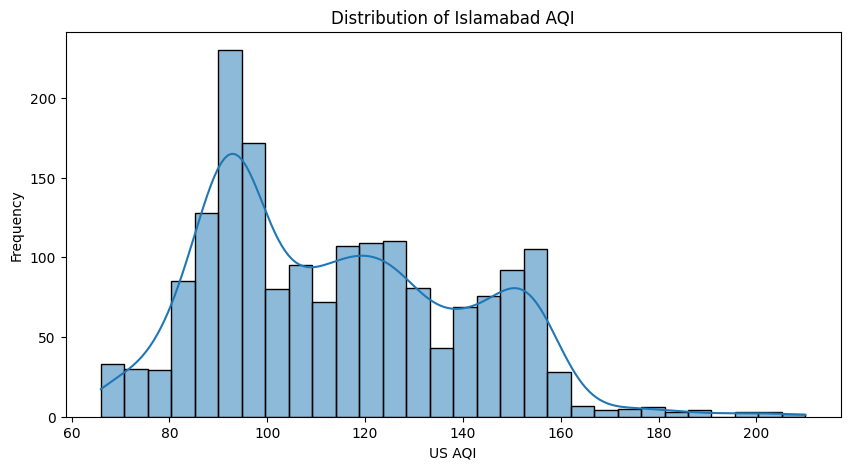

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(df["us_aqi"], bins=30, kde=True)

plt.title("Distribution of Islamabad AQI")
plt.xlabel("US AQI")
plt.ylabel("Frequency")
plt.show()

AQI over time

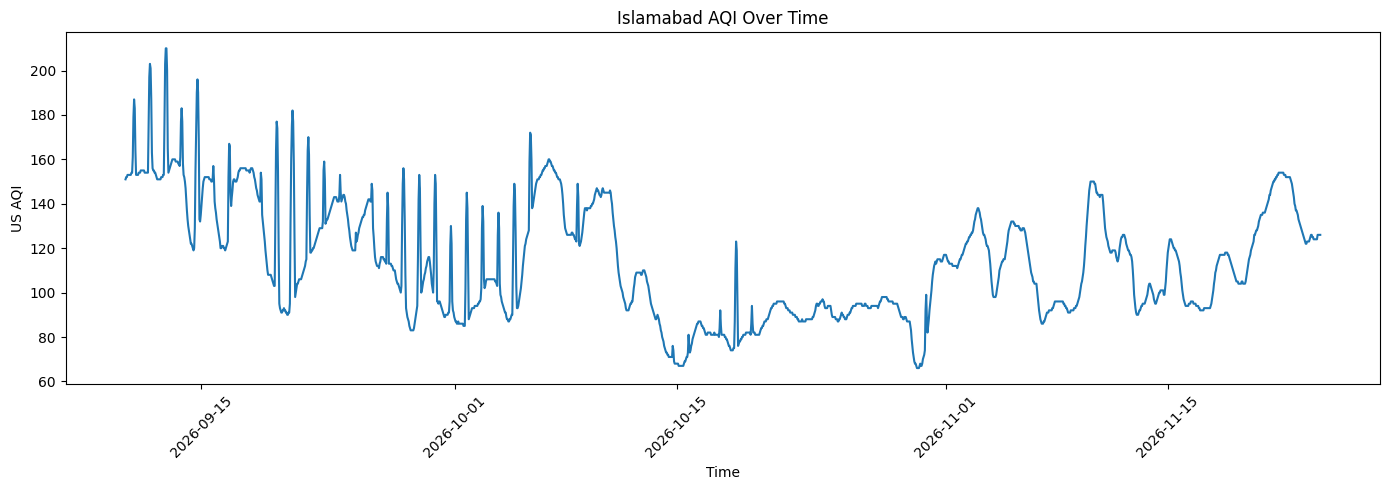

In [7]:
plt.figure(figsize=(14, 5))

plt.plot(df["time"], df["us_aqi"])

plt.title("Islamabad AQI Over Time")
plt.xlabel("Time")
plt.ylabel("US AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 7 — PM2.5 vs AQI

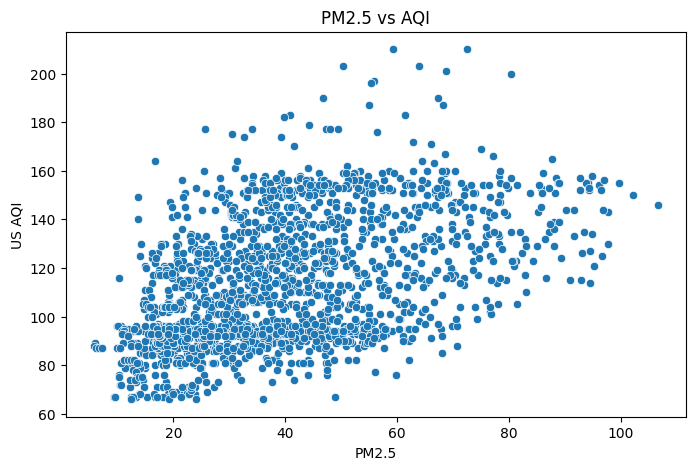

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="pm2_5",
    y="us_aqi"
)

plt.title("PM2.5 vs AQI")
plt.xlabel("PM2.5")
plt.ylabel("US AQI")
plt.show()

Correlation heatmap

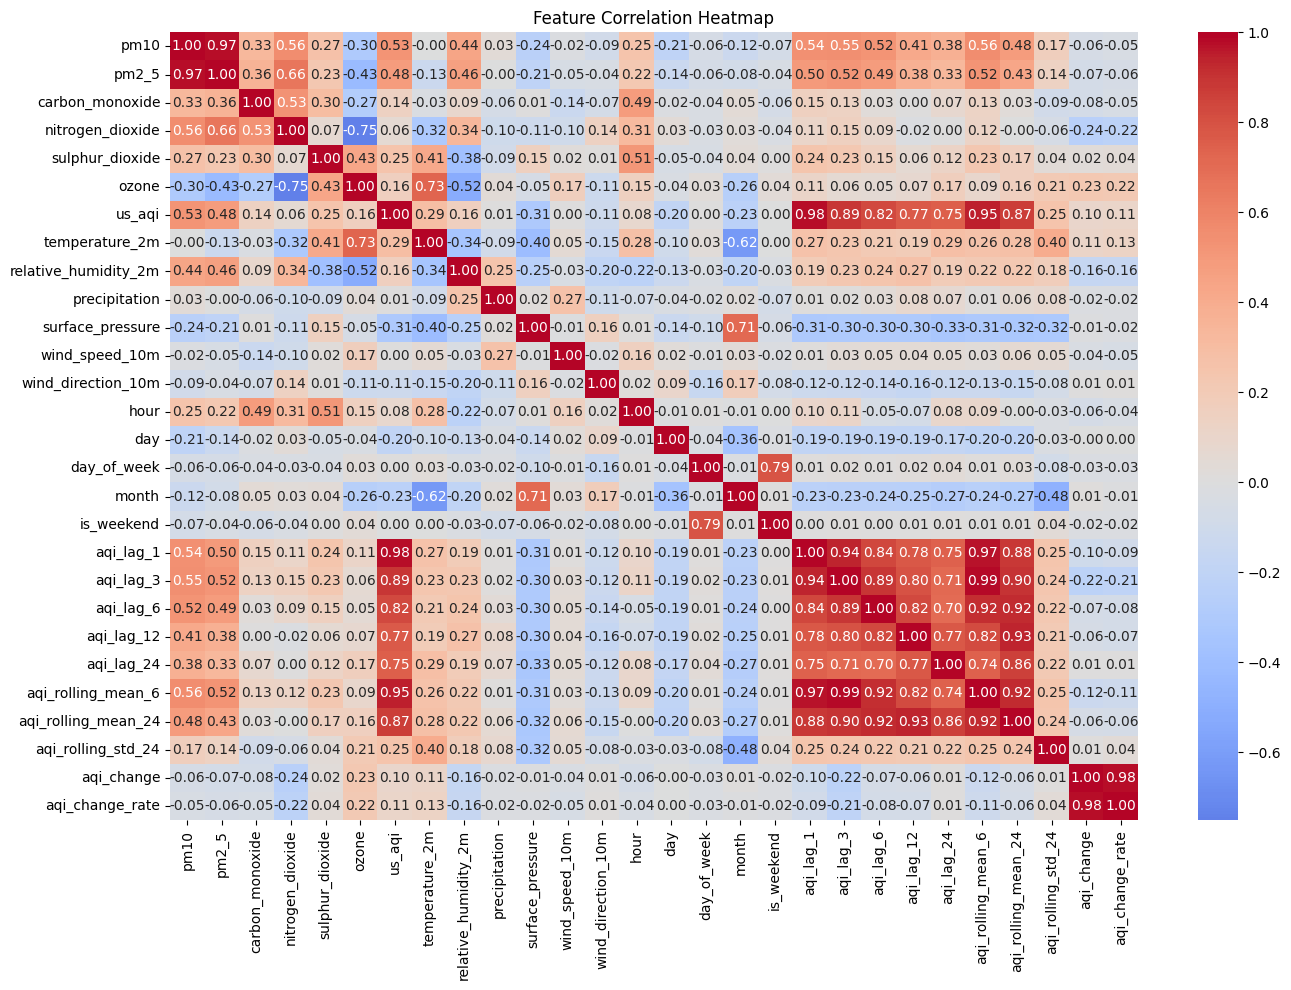

In [9]:
plt.figure(figsize=(14, 10))

numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

AQI by hour

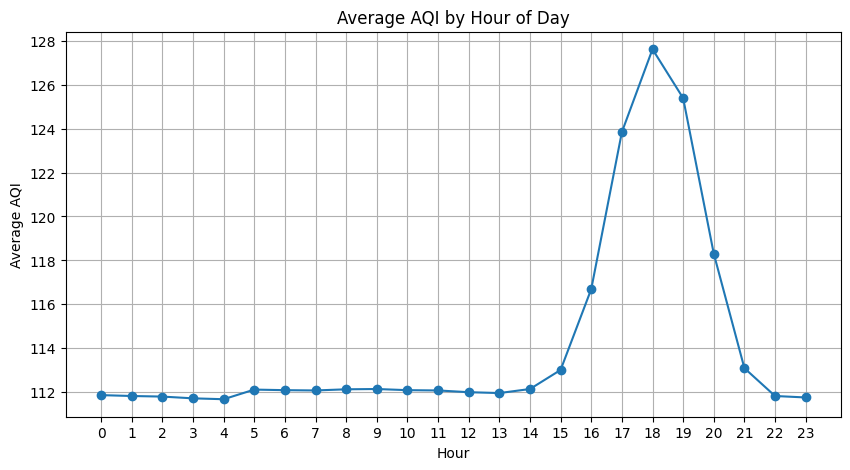

In [10]:
hourly_aqi = df.groupby("hour")["us_aqi"].mean()

plt.figure(figsize=(10, 5))

hourly_aqi.plot(kind="line", marker="o")

plt.title("Average AQI by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Average AQI")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

AQI by month

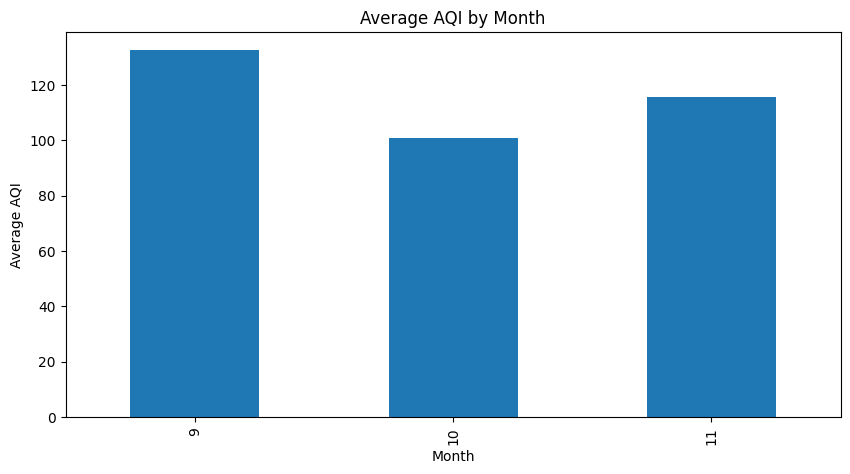

In [11]:
monthly_aqi = df.groupby("month")["us_aqi"].mean()

plt.figure(figsize=(10, 5))

monthly_aqi.plot(kind="bar")

plt.title("Average AQI by Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.show()

Check outliers

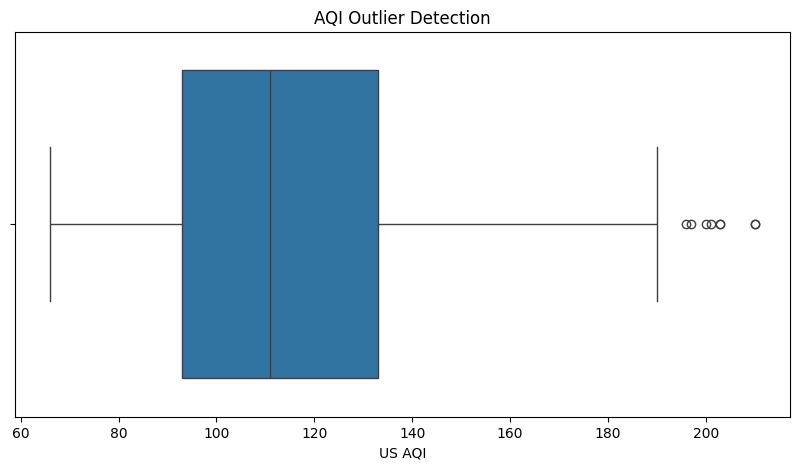

In [12]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["us_aqi"])

plt.title("AQI Outlier Detection")
plt.xlabel("US AQI")
plt.show()

EDA conclusion

## EDA Findings

- The dataset contains hourly AQI and weather observations for Islamabad, refreshed from the Open-Meteo API up to the current date each time the notebook runs.
- AQI shows variation over time, indicating that time-series forecasting is appropriate.
- PM2.5 and other pollutant variables show relationships with AQI.
- AQI varies across different hours of the day.
- Weather variables such as temperature, humidity, wind speed, and precipitation may contribute to AQI changes.
- Lag and rolling features provide historical AQI information that can help forecasting models.
- The dataset will be used for training and evaluating Ridge Regression, Random Forest, and LSTM models.